WEEK 5: MODEL EVALUATION

Existing ResNet50 Metrics:
   Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC              Evaluation
ResNet50      0.57   0.769231     0.2   0.31746   0.4008 Balanced small test set

Confusion Matrix:
[[47  3]
 [40 10]]

Total test samples: 100

Classification Report:
              precision    recall  f1-score   support

        Real       0.54      0.94      0.69        50
        Fake       0.77      0.20      0.32        50

    accuracy                           0.57       100
   macro avg       0.65      0.57      0.50       100
weighted avg       0.65      0.57      0.50       100


Error Analysis:
    Error Type                        Description  Count
 True Negative   Real correctly predicted as Real     47
False Positive Real incorrectly predicted as Fake      3
False Negative Fake incorrectly predicted as Real     40
 True Positive   Fake correctly predicted as Fake     10


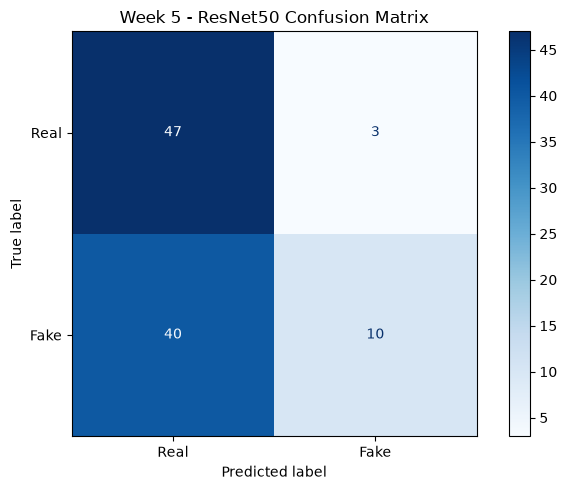

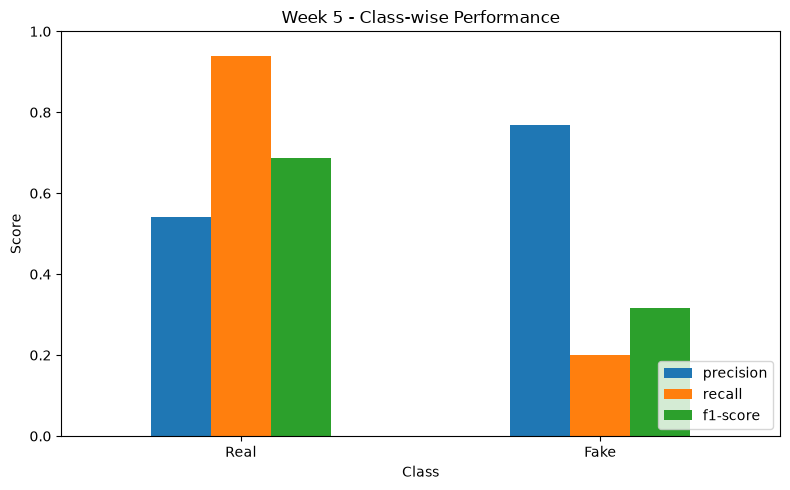

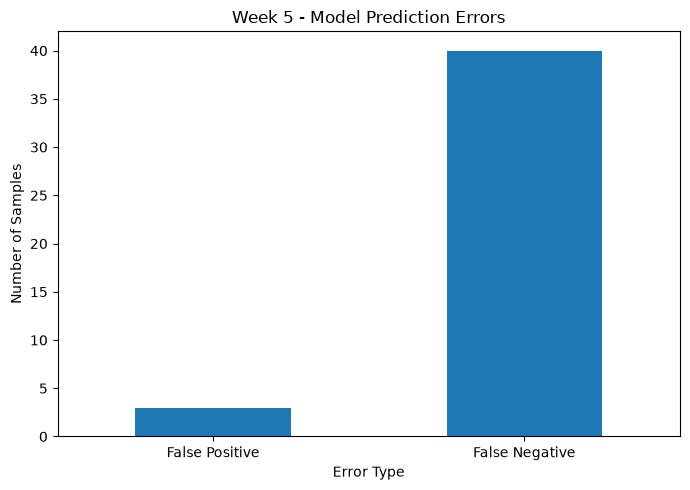


WEEK 5 EVALUATION COMPLETED

Files generated:
✓ week5_classification_report.csv
✓ week5_error_analysis.csv
✓ week5_final_evaluation_summary.csv
✓ week5_observations.txt
✓ week5_confusion_matrix.png
✓ week5_classwise_performance.png
✓ week5_error_analysis.png

Final Fake Recall: 20.0 %
False Negatives: 40

Next: Week 6 - Model Improvement and Tuning


In [ ]:
# ============================================================
# WEEK 5: RESNET50 MODEL EVALUATION AND ERROR ANALYSIS
# Dataset: Celeb-DF-v2
# Labels: 0 = Real, 1 = Fake
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. PROJECT PATHS
ROOT = Path(
    r"C:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION"
)

OUT = ROOT / "results"
FIG = OUT / "figures"

FIG.mkdir(parents=True, exist_ok=True)

metrics_file = OUT / "resnet50_preliminary_results.csv"
cm_file = OUT / "resnet50_confusion_matrix.csv"

# 2. CHECK FILES
if not metrics_file.exists():
    raise FileNotFoundError(f"Missing file: {metrics_file}")

if not cm_file.exists():
    raise FileNotFoundError(f"Missing file: {cm_file}")

# 3. LOAD EXISTING RESULTS
metrics_df = pd.read_csv(metrics_file)
cm_df = pd.read_csv(cm_file)

print("=" * 55)
print("WEEK 5: MODEL EVALUATION")
print("=" * 55)

print("\nExisting ResNet50 Metrics:")
print(metrics_df.to_string(index=False))

# 4. READ CONFUSION MATRIX
# Expected layout:
# Actual Real: 47 predicted Real, 3 predicted Fake
# Actual Fake: 40 predicted Real, 10 predicted Fake

cm = cm_df.iloc[:, -2:].apply(
    pd.to_numeric, errors="raise"
).to_numpy()

if cm.shape != (2, 2):
    raise ValueError("Confusion matrix must have 2 rows and 2 columns.")

tn, fp, fn, tp = cm.ravel()

total = int(cm.sum())

if total == 0:
    raise ValueError("Confusion matrix is empty.")

print("\nConfusion Matrix:")
print(cm)

print("\nTotal test samples:", total)

# 5. CALCULATE METRICS FROM CONFUSION MATRIX
accuracy = accuracy_score(
    [0] * int(tn + fp) + [1] * int(fn + tp),
    [0] * int(tn) + [1] * int(fp) +
    [0] * int(fn) + [1] * int(tp)
)

precision = precision_score(
    [0] * int(tn + fp) + [1] * int(fn + tp),
    [0] * int(tn) + [1] * int(fp) +
    [0] * int(fn) + [1] * int(tp),
    zero_division=0
)

recall = recall_score(
    [0] * int(tn + fp) + [1] * int(fn + tp),
    [0] * int(tn) + [1] * int(fp) +
    [0] * int(fn) + [1] * int(tp),
    zero_division=0
)

f1 = f1_score(
    [0] * int(tn + fp) + [1] * int(fn + tp),
    [0] * int(tn) + [1] * int(fp) +
    [0] * int(fn) + [1] * int(tp),
    zero_division=0
)

# 6. CLASSIFICATION REPORT
y_true = np.array(
    [0] * int(tn + fp) + [1] * int(fn + tp)
)

y_pred = np.array(
    [0] * int(tn) + [1] * int(fp) +
    [0] * int(fn) + [1] * int(tp)
)

report_dict = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Real", "Fake"],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Real", "Fake"],
        zero_division=0
    )
)

report_df.to_csv(
    OUT / "week5_classification_report.csv"
)

# 7. ERROR ANALYSIS
error_data = pd.DataFrame({
    "Error Type": [
        "True Negative",
        "False Positive",
        "False Negative",
        "True Positive"
    ],
    "Description": [
        "Real correctly predicted as Real",
        "Real incorrectly predicted as Fake",
        "Fake incorrectly predicted as Real",
        "Fake correctly predicted as Fake"
    ],
    "Count": [tn, fp, fn, tp]
})

error_data.to_csv(
    OUT / "week5_error_analysis.csv",
    index=False
)

print("\nError Analysis:")
print(error_data.to_string(index=False))

# 8. SAVE CONFUSION MATRIX FIGURE
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Real", "Fake"]
).plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("Week 5 - ResNet50 Confusion Matrix")
plt.tight_layout()

plt.savefig(
    FIG / "week5_confusion_matrix.png",
    dpi=300
)

plt.show()

# 9. CLASS-WISE PERFORMANCE CHART
class_metrics = report_df.loc[
    ["Real", "Fake"],
    ["precision", "recall", "f1-score"]
]

ax = class_metrics.plot(
    kind="bar",
    figsize=(8, 5)
)

ax.set_title("Week 5 - Class-wise Performance")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_xlabel("Class")
ax.legend(loc="lower right")

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIG / "week5_classwise_performance.png",
    dpi=300
)

plt.show()

# 10. ERROR COUNT CHART
error_counts = pd.Series({
    "False Positive": fp,
    "False Negative": fn
})

fig, ax = plt.subplots(figsize=(7, 5))

error_counts.plot(
    kind="bar",
    ax=ax
)

ax.set_title("Week 5 - Model Prediction Errors")
ax.set_ylabel("Number of Samples")
ax.set_xlabel("Error Type")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    FIG / "week5_error_analysis.png",
    dpi=300
)

plt.show()

# 11. SAVE EVALUATION SUMMARY
summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "Total Samples",
        "True Negative",
        "False Positive",
        "False Negative",
        "True Positive"
    ],
    "Value": [
        accuracy,
        precision,
        recall,
        f1,
        float(metrics_df.iloc[0]["ROC-AUC"]),
        total,
        tn,
        fp,
        fn,
        tp
    ]
})

summary.to_csv(
    OUT / "week5_final_evaluation_summary.csv",
    index=False
)

# 12. FINAL OBSERVATIONS
observations = f"""
WEEK 5: RESNET50 EVALUATION SUMMARY

Dataset: Celeb-DF-v2
Evaluation type: Preliminary balanced test set

Total samples: {total}

Accuracy: {accuracy:.4f}
Precision (Fake): {precision:.4f}
Recall (Fake): {recall:.4f}
F1-Score (Fake): {f1:.4f}

True Negative: {tn}
False Positive: {fp}
False Negative: {fn}
True Positive: {tp}

OBSERVATIONS:
1. The model correctly identifies {int(tn)} real samples.
2. The model correctly identifies {int(tp)} fake samples.
3. The model incorrectly classifies {int(fn)} fake samples as real.
4. Fake-class recall is low and needs improvement.
5. Further model optimization and threshold analysis are required.

LIMITATION:
This analysis uses an existing 100-sample confusion matrix.
Individual predictions and prediction probabilities are unavailable.
Therefore, ROC-AUC is retained from the existing results CSV.
An ROC curve and image-level error analysis cannot be generated.
"""

(OUT / "week5_observations.txt").write_text(
    observations,
    encoding="utf-8"
)

# 13. COMPLETION
print("\n" + "=" * 55)
print("WEEK 5 EVALUATION COMPLETED")
print("=" * 55)

print("\nFiles generated:")
for file in [
    OUT / "week5_classification_report.csv",
    OUT / "week5_error_analysis.csv",
    OUT / "week5_final_evaluation_summary.csv",
    OUT / "week5_observations.txt",
    FIG / "week5_confusion_matrix.png",
    FIG / "week5_classwise_performance.png",
    FIG / "week5_error_analysis.png"
]:
    print("✓", file.name)

print("\nFinal Fake Recall:", round(recall * 100, 2), "%")
print("False Negatives:", int(fn))
print("\nNext: Week 6 - Model Improvement and Tuning")
